# Basketball Free-Throw Simulation and Statistical Analysis
**Course:** Simulation and Modeling Lab (CSE 413), UITS

## 1. Introduction and Objectives
A player shoots a free throw. Every shot is a little different (the angle and the speed are never exactly the same), so some shots go in and some miss. We use Python to **simulate** thousands of shots (Monte Carlo) and then use **statistics** to interpret the results.

**Objectives**
- Build a mathematical model of a free throw using projectile motion.
- Draw the court and animate the shots, including made and missed shots.
- Add random variation in shooting angle and release speed.
- Run a Monte Carlo simulation with many repeated shots.
- Compare different shooting angles and different shooting conditions.
- Analyse the results with descriptive statistics, a chi-square test and a t-test.
- Explain what the results do and do not mean.

**Research questions**
1. Does the shooting angle change the chance of scoring (among the angles we test)?
2. Does pressure (a less steady shooter) make the shots less accurate?

**How to run:** `Runtime → Run all`, in order from the top. The animation cell needs about 1 minute. Each random section sets its own seed, so every section gives the same numbers each time you run it.

### Import necessary libraries

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.patches as patches      # to draw the ball, backboard and player
import matplotlib.animation as animation  # for the animated shot
from IPython.display import Video, Markdown, display  # show the video and formatted text

In [2]:
!apt-get install -y ffmpeg -qq  # needed to save the animation as a video

## 2. Mathematical Model and Assumptions

**Projectile motion.** The ball leaves the hands at height $h_0$ with speed $v$ and angle $\theta$. Ignoring air resistance:

$$x(t) = v\cos\theta \cdot t \qquad\qquad y(t) = h_0 + v\sin\theta \cdot t - \tfrac{1}{2} g t^2$$

**When does the ball reach the hoop?** The ball must come *down* to the rim height (3.05 m). Solving $y(t) = 3.05$ gives

$$t_{rim} = \frac{v\sin\theta + \sqrt{(v\sin\theta)^2 - 2g(3.05 - h_0)}}{g}$$

and the ball crosses the rim height at $x_{rim} = v\cos\theta \cdot t_{rim}$.

**Miss distance** = $x_{rim}$ − (distance to the hoop centre). Negative means the shot was *short*, positive means *long*.

**When is a shot made?** The hoop is wider than the ball, but a ball coming in at a flat angle "sees" a narrower hoop (like looking at a circle from the side). If the ball enters at angle $\phi$ below horizontal, it passes the rim edges cleanly when

$$|\text{miss distance}| \le R_{hoop} - \frac{r_{ball}}{\sin\phi}$$

So a higher arc (bigger $\phi$) gives a bigger target. This is a simplified rule that treats the ball's path near the rim as a straight line.

**Random variables (the shot-to-shot differences):**
- Shooting angle: $\Theta \sim Normal(\theta,\ 0.6^\circ)$
- Release speed: $V \sim Normal(v_{ideal},\ 0.6\%\ \text{of}\ v_{ideal})$

where $v_{ideal}$ is the speed that sends the ball exactly through the hoop centre for the chosen angle. So the shooter aims perfectly *on average*, and only random variation causes misses.

**Assumptions**
- No air resistance and no spin.
- Touching the rim counts as a miss (no rattling in), and there are no bank shots.
- The release point is fixed, and every shot is independent of the others.
- The values 0.6° and 0.6% are chosen to behave like a good shooter. They are **not** measured from real players, and the results depend on them.

### 2.1 Constants and functions
Real basketball measurements: the hoop is 4.19 m from the free-throw line and 3.05 m high. The hoop diameter is 45.7 cm and the ball diameter is 23.9 cm.

In [3]:
g = 9.8               # gravity (m/s^2)
hoop_x = 4.19         # free-throw line to hoop centre (m)
rim_height = 3.05     # rim height (m)
release_height = 2.2  # height of the ball when it leaves the hands (m)
rim_radius = 0.2285   # hoop radius (m)
ball_radius = 0.1195  # ball radius (m)

angle_sd = 0.6        # standard deviation of the shooting angle (degrees)
speed_sd_pct = 0.006  # standard deviation of the speed (0.6% of the ideal speed)

In [4]:
def ideal_speed(angle):
    # speed that sends the ball exactly through the hoop centre for this angle
    th = np.radians(angle)
    return np.sqrt(g * hoop_x**2 / (2 * np.cos(th)**2 * (hoop_x * np.tan(th) - (rim_height - release_height))))

def shoot(angle, speed):
    # simulates shots (works for one shot or for arrays of shots)
    th = np.radians(angle)
    vx = speed * np.cos(th)
    vy = speed * np.sin(th)
    disc = np.maximum(vy**2 - 2 * g * (rim_height - release_height), 0)
    t_rim = (vy + np.sqrt(disc)) / g                # time when the ball comes down to rim height
    error = vx * t_rim - hoop_x                     # miss distance (m): negative = short, positive = long
    vy_rim = vy - g * t_rim                         # vertical speed at the rim (negative = going down)
    entry_angle = np.arctan2(np.abs(vy_rim), vx)    # angle at which the ball enters the hoop
    tolerance = rim_radius - ball_radius / np.sin(entry_angle)  # allowed distance from the hoop centre
    made = np.abs(error) <= tolerance               # True = scored (a ball that never reaches the rim is a miss)
    return error, tolerance, made, np.degrees(entry_angle), t_rim

def ball_position(angle, speed, t):
    th = np.radians(angle)
    x = speed * np.cos(th) * t
    y = release_height + speed * np.sin(th) * t - 0.5 * g * t**2
    return x, y

def format_p(p):
    # prints a p-value properly (a tiny p-value is never shown as 0.0000)
    if p == 0:
        return 'p < 0.0001 (smaller than the computer can store)'
    if p < 0.0001:
        return f'p < 0.0001 (p = {p:.2e})'
    return f'p = {p:.4f}'

## 3. Basketball Court Visualization

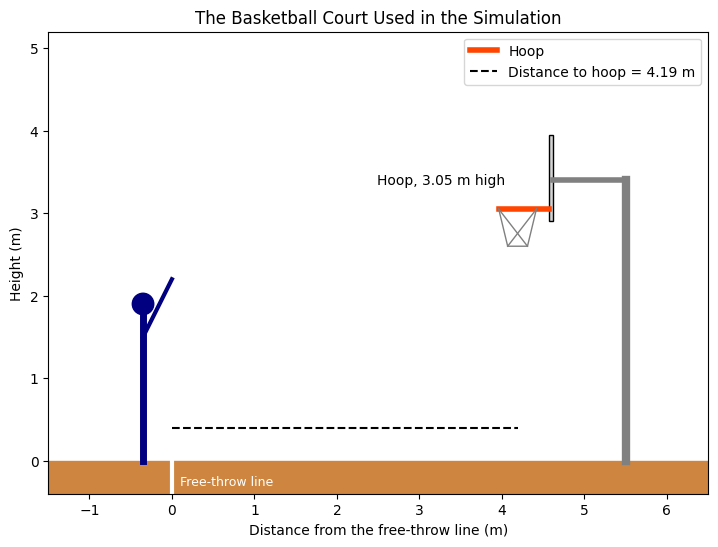

In [5]:
def draw_court(ax):
    board_x = hoop_x + rim_radius + 0.15
    ax.add_patch(patches.Rectangle((-1.5, -0.4), 8, 0.4, color='peru'))               # floor
    ax.plot([0, 0], [-0.4, 0], color='white', linewidth=3)                             # free-throw line
    ax.plot([5.5, 5.5], [0, 3.4], color='gray', linewidth=6)                           # support pole
    ax.plot([board_x + 0.05, 5.5], [3.4, 3.4], color='gray', linewidth=4)
    ax.add_patch(patches.Rectangle((board_x, 2.9), 0.05, 1.05, color='lightgray', ec='black'))  # backboard
    ax.plot([hoop_x - rim_radius, board_x], [rim_height, rim_height], color='orangered', linewidth=4, label='Hoop')
    # net
    ax.plot([hoop_x - rim_radius, hoop_x - 0.12, hoop_x + 0.12, hoop_x + rim_radius],
            [rim_height, rim_height - 0.45, rim_height - 0.45, rim_height], color='gray', linewidth=1)
    ax.plot([hoop_x - rim_radius, hoop_x + 0.12], [rim_height, rim_height - 0.45], color='gray', linewidth=1)
    ax.plot([hoop_x + rim_radius, hoop_x - 0.12], [rim_height, rim_height - 0.45], color='gray', linewidth=1)
    # simple shooter
    ax.add_patch(patches.Circle((-0.35, 1.9), 0.13, color='navy'))
    ax.plot([-0.35, -0.35], [0, 1.75], color='navy', linewidth=5)
    ax.plot([-0.35, 0], [1.5, release_height], color='navy', linewidth=3)
    ax.set_xlim(-1.5, 6.5)
    ax.set_ylim(-0.4, 5.2)
    ax.set_aspect('equal')
    ax.set_xlabel('Distance from the free-throw line (m)')
    ax.set_ylabel('Height (m)')

fig, ax = plt.subplots(figsize=(10, 6))
draw_court(ax)
ax.plot([0, hoop_x], [0.4, 0.4], 'k--', label=f'Distance to hoop = {hoop_x} m')
ax.text(0.1, -0.3, 'Free-throw line', color='white', fontsize=9)
ax.text(hoop_x - 1.7, rim_height + 0.3, f'Hoop, {rim_height} m high', fontsize=10)
ax.set_title('The Basketball Court Used in the Simulation')
ax.legend(loc='upper right')
plt.show()

## 4. Animated Free-Throw Simulation
First we shoot 30 times with a 55° angle. Each shot gets a random angle and speed (see Section 5). The first 6 shots are printed and animated.

In [6]:
np.random.seed(42)  # fixed seed -> same results every run

demo_angle = 55
demo_best = ideal_speed(demo_angle)
demo_angles = np.random.normal(demo_angle, angle_sd, 30)
demo_speeds = np.random.normal(demo_best, speed_sd_pct * demo_best, 30)
demo_error, demo_tol, demo_made, demo_entry, demo_t_rim = shoot(demo_angles, demo_speeds)
demo_x_rim = hoop_x + demo_error   # where each ball crosses the rim height

for i in range(6):
    result = 'MADE' if demo_made[i] else 'MISSED'
    print(f'Shot {i+1}: angle = {demo_angles[i]:.2f} deg, speed = {demo_speeds[i]:.2f} m/s, '
          f'miss distance = {demo_error[i]*100:+.1f} cm -> {result}')

Shot 1: angle = 55.30 deg, speed = 7.11 m/s, miss distance = -4.6 cm -> MADE
Shot 2: angle = 54.92 deg, speed = 7.22 m/s, miss distance = +11.5 cm -> MISSED
Shot 3: angle = 55.39 deg, speed = 7.14 m/s, miss distance = -1.4 cm -> MADE
Shot 4: angle = 55.91 deg, speed = 7.09 m/s, miss distance = -9.6 cm -> MISSED
Shot 5: angle = 54.86 deg, speed = 7.17 m/s, miss distance = +5.4 cm -> MADE
Shot 6: angle = 54.86 deg, speed = 7.08 m/s, miss distance = -6.9 cm -> MISSED


### How the ball is drawn
- **Until the ball reaches the rim height**, its position comes directly from the projectile equations in Section 2. This is the part that matches the mathematics exactly.
- **After that**, the drawing is only a visual effect and is not used in any statistics. A made shot drops through the net. A missed shot bounces back off the rim. There is no physics engine, just a simple change of the ball's velocity at the rim.

Missed shots also get a red path and a red **X** at the point where the ball crossed the rim height. Made shots get a green path and a green dot.

In [7]:
def after_rim(angle, speed, made, t_rim):
    # position and velocity of the ball at the moment it reaches the rim height
    th = np.radians(angle)
    x_rim, y_rim = ball_position(angle, speed, t_rim)
    vx = speed * np.cos(th)
    vy = speed * np.sin(th) - g * t_rim
    if made:
        return x_rim, y_rim, 0.2 * vx, vy            # the net slows the ball and it drops through
    else:
        return x_rim, y_rim, -0.6 * vx, -0.4 * vy    # the ball bounces back off the rim (display only)

def animated_ball(angle, speed, t, made, t_rim):
    # exact projectile motion before the rim, simple drop or bounce after it
    x, y = ball_position(angle, speed, t)
    x_rim, y_rim, new_vx, new_vy = after_rim(angle, speed, made, t_rim)
    dt = np.maximum(t - t_rim, 0)
    x_after = x_rim + new_vx * dt
    y_after = y_rim + new_vy * dt - 0.5 * g * dt**2
    return np.where(t > t_rim, x_after, x), np.where(t > t_rim, y_after, y)

def total_time(angle, speed, made, t_rim):
    # time until the ball reaches the floor
    x_rim, y_rim, new_vx, new_vy = after_rim(angle, speed, made, t_rim)
    return t_rim + (new_vy + np.sqrt(new_vy**2 + 2 * g * (y_rim - ball_radius))) / g

The video is saved with FFmpeg and shown below. The ball spins and the scoreboard counts the made shots.

In [8]:
n_anim = 6            # number of shots in the animation
frames_per_shot = 60  # 45 frames of flight + 15 frames of pause
move_frames = 45
video_path = '/content/Basketball_Free_Throw_Animation.mp4'

fig, ax = plt.subplots(figsize=(10, 6))

def update_plot(i):
    ax.clear()
    draw_court(ax)
    shot = i // frames_per_shot
    step = i % frames_per_shot
    frac = min(step / move_frames, 1)           # how far the shot has progressed (0 to 1)
    a, v, made, t_rim = demo_angles[shot], demo_speeds[shot], demo_made[shot], demo_t_rim[shot]
    t = frac * total_time(a, v, made, t_rim)

    passed_rim = t >= t_rim
    color = ('green' if made else 'red') if passed_rim else 'gray'

    # path so far and the ball
    tt = np.linspace(0, t, 50)
    px, py = animated_ball(a, v, tt, made, t_rim)
    ax.plot(px, py, '--', color=color, alpha=0.7, label='Ball path')
    ax.add_patch(patches.Circle((px[-1], py[-1]), ball_radius, color='darkorange', ec='black', label='Basketball'))
    for ang in [8 * frac, 8 * frac + np.pi / 2]:   # two lines on the ball so we can see it spin
        ax.plot([px[-1] - ball_radius * np.cos(ang), px[-1] + ball_radius * np.cos(ang)],
                [py[-1] - ball_radius * np.sin(ang), py[-1] + ball_radius * np.sin(ang)], 'k', linewidth=1)

    # scoreboard and result
    attempts = shot + int(passed_rim)
    made_so_far = int(np.sum(demo_made[:shot])) + int(made and passed_rim)
    ax.text(-1.3, 5.0, f'Shot {shot + 1} of {n_anim}\nScore: {made_so_far} made / {attempts} shots', fontsize=12, va='top')
    if passed_rim:
        cm = abs(demo_error[shot]) * 100
        side = 'short' if demo_error[shot] < 0 else 'long'
        if made:
            ax.plot(demo_x_rim[shot], rim_height, 'o', color='green', markersize=10, label='Made (inside the hoop)')
            ax.text(2.4, 4.55, 'MADE!', color='green', fontsize=30, fontweight='bold', ha='center')
        else:
            ax.plot(demo_x_rim[shot], rim_height, 'X', color='red', markersize=12, label='Missed (rim or hoop)')
            if cm < rim_radius * 100:
                detail = f'hit the rim, {cm:.0f} cm {side}'
            else:
                detail = f'{cm:.0f} cm {side}'
            ax.text(2.4, 4.55, 'MISSED!', color='red', fontsize=30, fontweight='bold', ha='center')
            ax.text(2.4, 4.2, detail, color='red', fontsize=12, ha='center')
    ax.set_title(f'Basketball Free-Throw Simulation (angle about {demo_angle} degrees)')
    ax.legend(loc='upper right', fontsize=9)

ani = animation.FuncAnimation(fig, update_plot, frames=n_anim * frames_per_shot, interval=50)
ani.save(video_path, writer='ffmpeg', fps=30)  # 30 frames per second
plt.close()  # hide the extra static figure

Video(video_path, embed=True)

## 5. Random Shooting Variation
No shooter repeats a shot exactly. For every shot, Python draws:
- a random angle: `np.random.normal(angle, 0.6)` (most shots are within about ±1.2° of the aimed angle)
- a random speed: `np.random.normal(ideal_speed, 0.6% of ideal_speed)`

The graph shows the same 30 shots from Section 4. Green paths are made shots and red paths are missed shots. Their paths are almost the same until the ball reaches the hoop, but the small differences decide whether it scores.

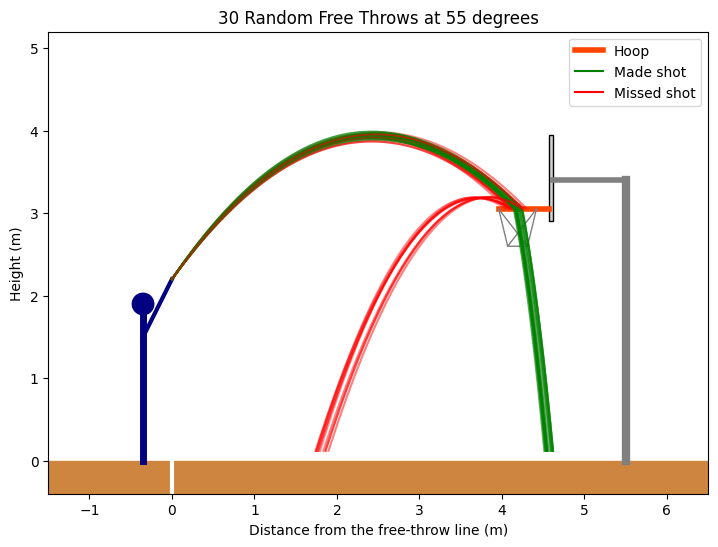

Made 20 out of 30 shots


In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
draw_court(ax)
for i in range(30):
    t = np.linspace(0, total_time(demo_angles[i], demo_speeds[i], demo_made[i], demo_t_rim[i]), 150)
    x, y = animated_ball(demo_angles[i], demo_speeds[i], t, demo_made[i], demo_t_rim[i])
    ax.plot(x, y, color='green' if demo_made[i] else 'red', alpha=0.5)
ax.plot([], [], color='green', label='Made shot')
ax.plot([], [], color='red', label='Missed shot')
ax.set_title('30 Random Free Throws at 55 degrees')
ax.legend(loc='upper right')
plt.show()
print(f'Made {demo_made.sum()} out of 30 shots')

## 6. Monte Carlo Simulation
**Experiment 1: Shooting angle.** We test 6 angles. For each angle we simulate **5000 shots**, each with a random angle and speed. Then we record the miss distance, whether the shot was made, and the entry angle. The same number of shots for every angle makes the comparison fair.

In [10]:
np.random.seed(43)  # this section has its own seed

angles = np.array([45, 50, 55, 60, 65, 70])
n_shots = 5000

all_errors = []   # miss distances in cm (one array per angle)
all_made = []     # True/False for each shot
all_entry = []    # entry angles
all_tol = []      # average allowed distance from the hoop centre (cm)

for a in angles:
    v_ideal = ideal_speed(a)
    shot_angles = np.random.normal(a, angle_sd, n_shots)
    shot_speeds = np.random.normal(v_ideal, speed_sd_pct * v_ideal, n_shots)
    error, tol, made, entry, t_rim = shoot(shot_angles, shot_speeds)
    all_errors.append(error * 100)
    all_made.append(made)
    all_entry.append(entry)
    all_tol.append(np.mean(tol) * 100)
    print(f'{a} degrees: ideal speed = {v_ideal:.2f} m/s, {made.sum()} of {n_shots} shots made')

45 degrees: ideal speed = 7.18 m/s, 20 of 5000 shots made
50 degrees: ideal speed = 7.09 m/s, 2055 of 5000 shots made
55 degrees: ideal speed = 7.14 m/s, 3266 of 5000 shots made
60 degrees: ideal speed = 7.33 m/s, 3640 of 5000 shots made
65 degrees: ideal speed = 7.69 m/s, 3409 of 5000 shots made
70 degrees: ideal speed = 8.31 m/s, 3036 of 5000 shots made


## 7. Descriptive Statistical Analysis
For each angle: the success rate, the mean and standard deviation of the miss distance, the average size of the miss, and the average entry angle.

In [11]:
success_rate = np.array([np.mean(m) * 100 for m in all_made])
sd_by_angle = np.array([np.std(e, ddof=1) for e in all_errors])

print('Angle | Success % | Mean error (cm) | Std (cm) | Mean |error| (cm) | Median |error| (cm) | Entry angle')
for i, a in enumerate(angles):
    err = all_errors[i]
    print(f'{a:>5} | {success_rate[i]:>9.1f} | {np.mean(err):>15.2f} | {sd_by_angle[i]:>8.2f} | '
          f'{np.mean(np.abs(err)):>17.2f} | {np.median(np.abs(err)):>19.2f} | {np.mean(all_entry[i]):>9.1f}')

best_index = np.argmax(success_rate)
best_angle = angles[best_index]
print(f'\nHighest success rate among the tested angles: {best_angle} degrees with {success_rate[best_index]:.1f}%')

Angle | Success % | Mean error (cm) | Std (cm) | Mean |error| (cm) | Median |error| (cm) | Entry angle
   45 |       0.4 |           -0.03 |     7.40 |              5.86 |                4.85 |      30.7
   50 |      41.1 |           -0.14 |     6.43 |              5.14 |                4.33 |      38.1
   55 |      65.3 |           -0.11 |     6.38 |              5.09 |                4.29 |      45.6
   60 |      72.8 |           -0.19 |     7.20 |              5.75 |                4.88 |      53.0
   65 |      68.2 |           -0.14 |     8.90 |              7.19 |                6.24 |      60.1
   70 |      60.7 |            0.06 |    11.64 |              9.25 |                7.75 |      66.9

Highest success rate among the tested angles: 60 degrees with 72.8%


## 8. Shooting Angle Comparison

### 8.1 Success percentage at different angles

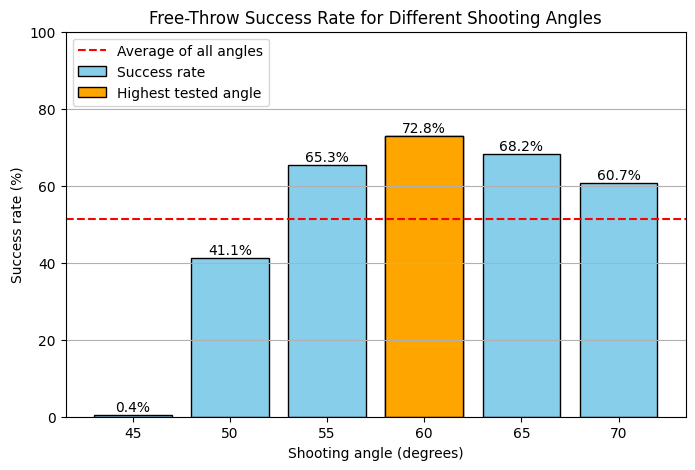

In [12]:
plt.figure(figsize=(8, 5))
plt.bar(angles.astype(str), success_rate, color='skyblue', edgecolor='black', label='Success rate')
plt.bar(str(best_angle), success_rate[best_index], color='orange', edgecolor='black', label='Highest tested angle')
plt.axhline(np.mean(success_rate), color='r', linestyle='--', label='Average of all angles')
for i in range(len(angles)):
    plt.text(i, success_rate[i] + 1, f'{success_rate[i]:.1f}%', ha='center')
plt.title('Free-Throw Success Rate for Different Shooting Angles')
plt.xlabel('Shooting angle (degrees)')
plt.ylabel('Success rate (%)')
plt.ylim(0, 100)
plt.legend(loc='upper left')
plt.grid(axis='y')
plt.show()

### 8.2 Histogram of miss distances
Each histogram shows how far the ball landed from the hoop centre (0 cm). Green lines show the average "made zone". A shot inside this zone goes in. Flat shots have a tiny zone, and high shots have a wide zone but are harder to control.

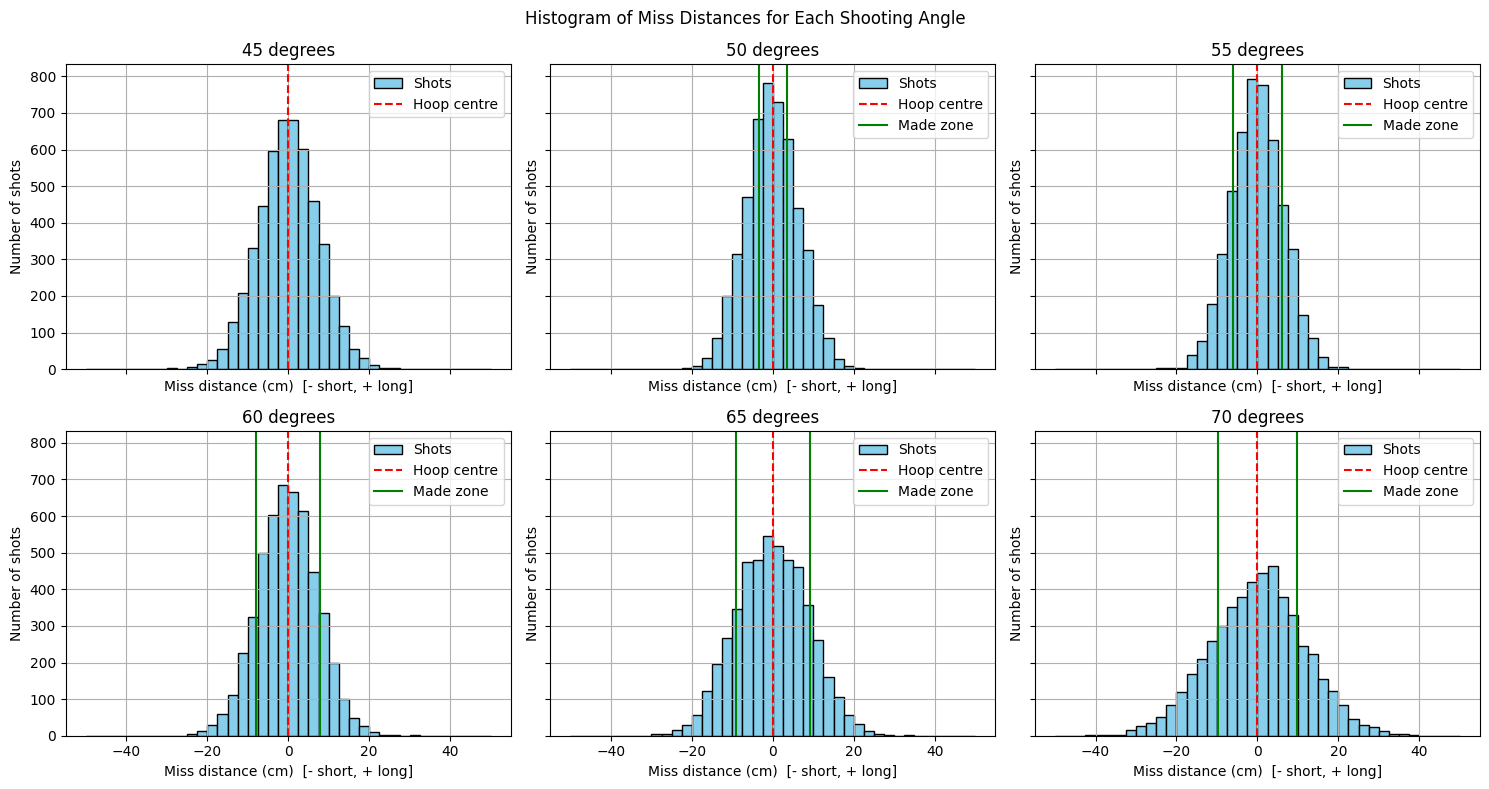

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.flatten()
bins = np.arange(-50, 51, 2.5)

for i, a in enumerate(angles):
    axes[i].hist(all_errors[i], bins=bins, color='skyblue', edgecolor='black', label='Shots')
    axes[i].axvline(0, color='red', linestyle='--', label='Hoop centre')
    if all_tol[i] > 0:
        axes[i].axvline(all_tol[i], color='green', linestyle='-', label='Made zone')
        axes[i].axvline(-all_tol[i], color='green', linestyle='-')
    axes[i].set_title(f'{a} degrees')
    axes[i].set_xlabel('Miss distance (cm)  [- short, + long]')
    axes[i].set_ylabel('Number of shots')
    axes[i].legend(loc='upper right')
    axes[i].grid(True)

plt.suptitle('Histogram of Miss Distances for Each Shooting Angle')
plt.tight_layout()
plt.show()

## 9. Chi-Square Test of Homogeneity
**Question:** Is the chance of scoring the same at all six tested angles?

**Which chi-square test is this?** We have **several groups** (the angles) and we ask whether they share the **same outcome pattern** (made / missed). That is a **chi-square test of homogeneity**.

**Hypotheses**
- H₀: The probability of scoring is the **same** at every tested angle (the angle has no effect).
- H₁: The probability of scoring is **not the same** at every angle (at least one angle is different).

Significance level: α = 0.05.

### Step 1: Observed frequency table (2 rows × 6 columns)

In [14]:
made_counts = np.array([m.sum() for m in all_made])
missed_counts = n_shots - made_counts
observed = np.array([made_counts, missed_counts])   # row 0 = made, row 1 = missed, one column per angle

print('Angle   ', *[f'{a:>7}' for a in angles])
print('Made    ', *[f'{c:>7}' for c in observed[0]])
print('Missed  ', *[f'{c:>7}' for c in observed[1]])

Angle         45      50      55      60      65      70
Made          20    2055    3266    3640    3409    3036
Missed      4980    2945    1734    1360    1591    1964


### Step 2: Expected frequencies
If H₀ is true, every angle has the same success rate, namely the overall rate of all shots. For a table, each expected frequency is

$$E = \frac{\text{row total} \times \text{column total}}{\text{grand total}}$$

For example, the expected number of made shots at one angle is (all made shots × shots at that angle) ÷ all shots. This uses the data only to say what "no angle effect" would look like.

In [15]:
row_totals = np.sum(observed, axis=1)    # total made, total missed
col_totals = np.sum(observed, axis=0)    # shots at each angle
grand_total = np.sum(observed)
expected = np.outer(row_totals, col_totals) / grand_total   # np.outer multiplies every row total by every column total

print('Expected made   ', *[f'{c:>7.1f}' for c in expected[0]])
print('Expected missed ', *[f'{c:>7.1f}' for c in expected[1]])
print(f'Smallest expected frequency: {expected.min():.1f} (should be at least 5 for the test to be reliable)')

Expected made     2571.0  2571.0  2571.0  2571.0  2571.0  2571.0
Expected missed   2429.0  2429.0  2429.0  2429.0  2429.0  2429.0
Smallest expected frequency: 2429.0 (should be at least 5 for the test to be reliable)


### Step 3: Chi-square statistic calculation

In [16]:
chi_square_stat = np.sum(((observed - expected) ** 2) / expected)

### Step 4: Degrees of freedom
For a two-way table: df = (number of rows − 1) × (number of columns − 1). Here that is (2 − 1) × (6 − 1) = 5.

In [17]:
number_of_rows, number_of_columns = observed.shape
df = (number_of_rows - 1) * (number_of_columns - 1)

### Step 5: Critical value and p-value

In [18]:
alpha = 0.05  # Significance level
critical_value = stats.chi2.ppf(1 - alpha, df)  # Critical value
chi_p_value = stats.chi2.sf(chi_square_stat, df)  # p-value (the same as 1 - cdf, but accurate for tiny values)
chi_df = df  # saved because the t-test below also uses the name df

### Display the results

In [19]:
print(f'Chi-square statistic: {chi_square_stat:.2f}')
print(f'Degrees of freedom: {df}')
print(f'Critical value (0.05 significance level): {critical_value:.2f}')
print(f'P-value: {format_p(chi_p_value)}')

Chi-square statistic: 7460.51
Degrees of freedom: 5
Critical value (0.05 significance level): 11.07
P-value: p < 0.0001 (smaller than the computer can store)


### Conclusion

In [20]:
if chi_square_stat > critical_value:
    print('Reject the null hypothesis. The probability of scoring is NOT the same at all tested angles, so the shooting angle affects scoring in this model.')
else:
    print('Fail to reject the null hypothesis. There is no evidence that the probability of scoring differs between the tested angles.')

Reject the null hypothesis. The probability of scoring is NOT the same at all tested angles, so the shooting angle affects scoring in this model.


## 10. T-Test: Normal Shooter vs Shooter Under Pressure
**Question:** Does pressure make the shots less accurate?

We take the angle with the highest success rate in Experiment 1 and simulate two new groups of 5000 shots:
- **Normal shooter:** the same noise as before.
- **Pressure shooter:** 1.5 times more variation in both angle and speed.

The measurement is the **absolute miss distance** (cm), a numerical value, so a **two-sample t-test** is appropriate.

**Hypotheses**
- H₀: The mean absolute miss distance is the same for both shooters (μ₁ = μ₂).
- H₁: The mean absolute miss distance is different (μ₁ ≠ μ₂).

**Assumptions of the independent-samples t-test**
1. The two groups are independent. This holds, because every shot is simulated separately.
2. The data are roughly normal, or the samples are large enough for the sample means to be roughly normal.
3. The two groups have equal variances (for the pooled version).

Assumptions 2 and 3 are only **approximately** true here. Absolute distances can never be negative, so they pile up near 0 and are right-skewed. The pressure group is also more spread out. We measure both below.

### Step 1: Define the two independent datasets

In [21]:
np.random.seed(44)  # this section has its own seed

v_best = ideal_speed(best_angle)

normal_angles = np.random.normal(best_angle, angle_sd, n_shots)
normal_speeds = np.random.normal(v_best, speed_sd_pct * v_best, n_shots)
pressure_angles = np.random.normal(best_angle, 1.5 * angle_sd, n_shots)
pressure_speeds = np.random.normal(v_best, 1.5 * speed_sd_pct * v_best, n_shots)

error_n, tol_n, made_n, entry_n, t_n = shoot(normal_angles, normal_speeds)
error_p, tol_p, made_p, entry_p, t_p = shoot(pressure_angles, pressure_speeds)

data1 = np.abs(error_n) * 100  # Sample 1: normal shooter (cm)
data2 = np.abs(error_p) * 100  # Sample 2: pressure shooter (cm)

print(f'Normal shooter success rate:   {np.mean(made_n) * 100:.1f}%')
print(f'Pressure shooter success rate: {np.mean(made_p) * 100:.1f}%')

Normal shooter success rate:   72.1%
Pressure shooter success rate: 54.2%


### Checking the assumptions

In [22]:
skew1, skew2 = stats.skew(data1), stats.skew(data2)
sd1, sd2 = np.std(data1, ddof=1), np.std(data2, ddof=1)
print(f'Skewness of Sample 1: {skew1:.2f}   Skewness of Sample 2: {skew2:.2f}   (0 would be perfectly symmetric)')
print(f'Standard deviation of Sample 1: {sd1:.2f} cm   Sample 2: {sd2:.2f} cm')
print(f'Ratio of standard deviations (Sample 2 / Sample 1): {sd2 / sd1:.2f}')

Skewness of Sample 1: 0.96   Skewness of Sample 2: 1.04   (0 would be perfectly symmetric)
Standard deviation of Sample 1: 4.37 cm   Sample 2: 6.56 cm
Ratio of standard deviations (Sample 2 / Sample 1): 1.50


### Step 2: Perform the two-sample t-test (pooled, equal variances)

In [23]:
t_statistic, p_value = stats.ttest_ind(data1, data2, equal_var=True)

### Calculate confidence interval for the difference of means

In [24]:
# mean difference
mean_diff = np.mean(data1) - np.mean(data2)

# sample sizes
n1, n2 = len(data1), len(data2)

# sample variances
s1_sq, s2_sq = np.var(data1, ddof=1), np.var(data2, ddof=1)

# pooled variance
sp_sq = ((n1 - 1) * s1_sq + (n2 - 1) * s2_sq) / (n1 + n2 - 2)

# standard error using pooled variance
std_err = np.sqrt(sp_sq * (1/n1 + 1/n2))

# degrees of freedom
df = n1 + n2 - 2
t_df = df

# 95% confidence interval
ci = stats.t.interval(0.95, df, loc=mean_diff, scale=std_err)

### Step 3: Display results

In [25]:
print(f'Normal shooter mean miss distance: {np.mean(data1):.2f} cm')
print(f'Pressure shooter mean miss distance: {np.mean(data2):.2f} cm')
print(f'Mean difference (normal - pressure): {mean_diff:.2f} cm')
print(f't-Statistic: {t_statistic:.2f}')
print(f'Degrees of Freedom: {df:.2f}')
print(f'p-Value: {format_p(p_value)}')
print(f'95% Confidence Interval of Mean Difference: [{ci[0]:.2f}, {ci[1]:.2f}] cm')

Normal shooter mean miss distance: 5.84 cm
Pressure shooter mean miss distance: 8.60 cm
Mean difference (normal - pressure): -2.76 cm
t-Statistic: -24.75
Degrees of Freedom: 9998.00
p-Value: p < 0.0001 (p = 2.51e-131)
95% Confidence Interval of Mean Difference: [-2.98, -2.54] cm


### Step 4: Conclusion

In [26]:
alpha = 0.05  # Significance level
if p_value < alpha:
    print('Reject the null hypothesis. The mean miss distances of the two shooters are significantly different.')
else:
    print('Fail to reject the null hypothesis. The mean miss distances are not significantly different.')

if mean_diff < 0:
    print(f'On average the pressure shooter missed by {abs(mean_diff):.2f} cm more (95% CI: {abs(ci[1]):.2f} to {abs(ci[0]):.2f} cm more).')
else:
    print(f'On average the pressure shooter missed by {abs(mean_diff):.2f} cm less (95% CI: {abs(ci[0]):.2f} to {abs(ci[1]):.2f} cm less).')

Reject the null hypothesis. The mean miss distances of the two shooters are significantly different.
On average the pressure shooter missed by 2.76 cm more (95% CI: 2.54 to 2.98 cm more).


### Step 5: Visualize the data

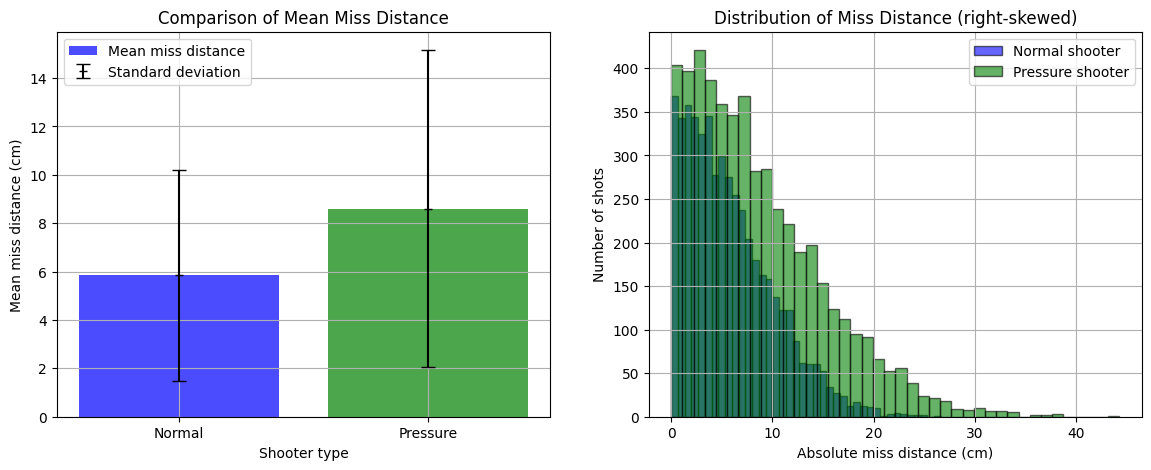

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(['Normal', 'Pressure'], [np.mean(data1), np.mean(data2)], color=['blue', 'green'], alpha=0.7, label='Mean miss distance')
axes[0].errorbar(['Normal', 'Pressure'], [np.mean(data1), np.mean(data2)],
                 yerr=[np.std(data1, ddof=1), np.std(data2, ddof=1)], fmt='k_', capsize=5, label='Standard deviation')
axes[0].set_title('Comparison of Mean Miss Distance')
axes[0].set_xlabel('Shooter type')
axes[0].set_ylabel('Mean miss distance (cm)')
axes[0].legend()
axes[0].grid(True)

axes[1].hist(data1, bins=40, alpha=0.6, color='blue', edgecolor='black', label='Normal shooter')
axes[1].hist(data2, bins=40, alpha=0.6, color='green', edgecolor='black', label='Pressure shooter')
axes[1].set_title('Distribution of Miss Distance (right-skewed)')
axes[1].set_xlabel('Absolute miss distance (cm)')
axes[1].set_ylabel('Number of shots')
axes[1].legend()
axes[1].grid(True)

plt.show()

## 11. Results and Discussion
The text below is written by Python from the actual simulation outputs above, so every number matches the results.

In [28]:
worst_index = np.argmin(success_rate)
lowest_sd_index = np.argmin(sd_by_angle)
highest_sd_index = np.argmax(sd_by_angle)
sk_text = f'{skew1:.2f} and {skew2:.2f}'
mean1, mean2 = np.mean(data1), np.mean(data2)
rate_n, rate_p = np.mean(made_n) * 100, np.mean(made_p) * 100

# ---- table of results
rows = ['| Angle | Success rate (%) | Std of miss distance (cm) | Mean absolute miss (cm) | Mean entry angle |',
        '|---|---|---|---|---|']
for i, a in enumerate(angles):
    rows.append(f'| {a}° | {success_rate[i]:.1f} | {sd_by_angle[i]:.2f} | {np.mean(np.abs(all_errors[i])):.2f} | {np.mean(all_entry[i]):.1f}° |')
table_text = '\n'.join(rows)

# ---- how the success rate changed
if 0 < best_index < len(angles) - 1:
    shape = (f'The success rate rose from {success_rate[0]:.1f}% at {angles[0]}° to a peak of {success_rate[best_index]:.1f}% at {best_angle}°, '
             f'then fell to {success_rate[-1]:.1f}% at {angles[-1]}°.')
elif best_index == len(angles) - 1:
    shape = f'The success rate rose from {success_rate[0]:.1f}% at {angles[0]}° to {success_rate[-1]:.1f}% at {angles[-1]}°, the highest value among the tested angles.'
else:
    shape = f'The success rate fell from {success_rate[0]:.1f}% at {angles[0]}° to {success_rate[-1]:.1f}% at {angles[-1]}°.'

zone_first = 'no made zone at all' if all_tol[0] <= 0 else f'{all_tol[0]:.1f} cm'
zone_last = 'no made zone at all' if all_tol[-1] <= 0 else f'{all_tol[-1]:.1f} cm'

lines = []
lines.append('### 11.1 Shooting angle results')
lines.append(table_text)
lines.append(f'Among the shooting angles tested in this simulation, **{best_angle}°** produced the highest success rate '
             f'(**{success_rate[best_index]:.1f}%**, {made_counts[best_index]} of {n_shots} shots) under the assumptions of the mathematical model. '
             f'The lowest success rate was at {angles[worst_index]}° ({success_rate[worst_index]:.1f}%). ' + shape)
both_effects = (all_tol[-1] > all_tol[0]) and (highest_sd_index > lowest_sd_index)
if both_effects:
    compete = (f' Two effects compete: a steeper arc gives a bigger target (the average allowed distance from the hoop centre changed from '
               f'{zone_first} at {angles[0]}° to {zone_last} at {angles[-1]}°), but it also spreads the shots out more '
               f'(the standard deviation grew from {sd_by_angle[lowest_sd_index]:.2f} cm at {angles[lowest_sd_index]}° to {sd_by_angle[highest_sd_index]:.2f} cm at {angles[highest_sd_index]}°).')
else:
    compete = ''
lines.append(f'**Variability.** The standard deviation of the miss distance was smallest at {angles[lowest_sd_index]}° ({sd_by_angle[lowest_sd_index]:.2f} cm) '
             f'and largest at {angles[highest_sd_index]}° ({sd_by_angle[highest_sd_index]:.2f} cm).' + compete)

lines.append('### 11.2 Chi-square test of homogeneity')
if chi_square_stat > critical_value:
    chi_decision = ('We reject H₀. The probability of scoring is **not** the same at all tested angles. In simple words: the differences in made shots '
                    'between the angles are too large to be explained by luck alone.')
else:
    chi_decision = 'We fail to reject H₀. The data give no evidence that the probability of scoring differs between the tested angles.'
lines.append(f'χ² = {chi_square_stat:.2f} with df = {chi_df}. The critical value at α = 0.05 is {critical_value:.2f}, and {format_p(chi_p_value)}. ' + chi_decision +
             f' The success rates ranged from {success_rate[worst_index]:.1f}% to {success_rate[best_index]:.1f}%, a spread of {success_rate[best_index] - success_rate[worst_index]:.1f} percentage points.')

lines.append('### 11.3 T-test: normal vs pressure')
if p_value < alpha:
    t_decision = 'We reject H₀: the mean absolute miss distances differ.'
else:
    t_decision = 'We fail to reject H₀: the mean absolute miss distances do not differ significantly.'
direction = 'more' if mean_diff < 0 else 'less'
lines.append(f'The normal shooter missed by {mean1:.2f} cm on average and the pressure shooter by {mean2:.2f} cm. '
             f'The pressure shooter missed by {abs(mean_diff):.2f} cm {direction} on average (95% CI: {min(abs(ci[0]), abs(ci[1])):.2f} to {max(abs(ci[0]), abs(ci[1])):.2f} cm {direction}). '
             f't = {t_statistic:.2f}, df = {t_df}, {format_p(p_value)}. ' + t_decision)
lines.append(f'**Cautions.** The miss distances are right-skewed (skewness {sk_text}) and the standard deviations differ by a factor of {sd2 / sd1:.2f}, '
             f'so the t-test assumptions are only approximately met. The large samples ({n1} shots per group) make the comparison less sensitive to the skewness, but this is an approximation, not a guarantee.')
if abs(rate_n - rate_p) >= 5:
    practical = 'so this difference is large enough to matter in the model, not just statistically detectable.'
else:
    practical = 'so although the difference may be statistically detectable, it is small and may not matter much in practice.'
lines.append(f'**Practical importance.** The success rate was {rate_n:.1f}% for the normal shooter and {rate_p:.1f}% under pressure, a difference of {rate_n - rate_p:.1f} percentage points, ' + practical)

lines.append('### 11.4 Do the findings answer the research questions?')
if chi_square_stat > critical_value:
    q1 = (f'**Question 1 (angle):** Yes, within the tested angles. The success rate depends on the angle in this model, and {best_angle}° had the highest rate.')
else:
    q1 = '**Question 1 (angle):** No evidence of an angle effect was found among the tested angles.'
if p_value < alpha:
    q2 = (f'**Question 2 (pressure):** Yes, in this model. The pressure shooter was less accurate ({mean2:.2f} cm vs {mean1:.2f} cm mean miss distance) and scored less often ({rate_p:.1f}% vs {rate_n:.1f}%).')
else:
    q2 = '**Question 2 (pressure):** No significant difference in accuracy was found.'
lines.append(q1)
lines.append(q2)
if both_effects and 0 < best_index < len(angles) - 1:
    meaning = (f'**What this means in the simplified model.** In the model, a flatter shot sees the hoop as a narrower opening, while a steeper shot sees a wider opening but its landing point is more spread out (see the table). '
               f'The balance between these two effects gave the highest success rate at {best_angle}° among the angles tested, under the chosen noise levels and the simplified scoring rule.')
else:
    meaning = (f'**What this means in the simplified model.** The highest success rate among the tested angles was at {best_angle}°, under the chosen noise levels and the simplified scoring rule. '
               f'The table shows how the size of the target and the spread of the shots changed with the angle.')
lines.append(meaning)
display(Markdown('\n\n'.join(lines)))

### 11.1 Shooting angle results

| Angle | Success rate (%) | Std of miss distance (cm) | Mean absolute miss (cm) | Mean entry angle |
|---|---|---|---|---|
| 45° | 0.4 | 7.40 | 5.86 | 30.7° |
| 50° | 41.1 | 6.43 | 5.14 | 38.1° |
| 55° | 65.3 | 6.38 | 5.09 | 45.6° |
| 60° | 72.8 | 7.20 | 5.75 | 53.0° |
| 65° | 68.2 | 8.90 | 7.19 | 60.1° |
| 70° | 60.7 | 11.64 | 9.25 | 66.9° |

Among the shooting angles tested in this simulation, **60°** produced the highest success rate (**72.8%**, 3640 of 5000 shots) under the assumptions of the mathematical model. The lowest success rate was at 45° (0.4%). The success rate rose from 0.4% at 45° to a peak of 72.8% at 60°, then fell to 60.7% at 70°.

**Variability.** The standard deviation of the miss distance was smallest at 55° (6.38 cm) and largest at 70° (11.64 cm). Two effects compete: a steeper arc gives a bigger target (the average allowed distance from the hoop centre changed from no made zone at all at 45° to 9.9 cm at 70°), but it also spreads the shots out more (the standard deviation grew from 6.38 cm at 55° to 11.64 cm at 70°).

### 11.2 Chi-square test of homogeneity

χ² = 7460.51 with df = 5. The critical value at α = 0.05 is 11.07, and p < 0.0001 (smaller than the computer can store). We reject H₀. The probability of scoring is **not** the same at all tested angles. In simple words: the differences in made shots between the angles are too large to be explained by luck alone. The success rates ranged from 0.4% to 72.8%, a spread of 72.4 percentage points.

### 11.3 T-test: normal vs pressure

The normal shooter missed by 5.84 cm on average and the pressure shooter by 8.60 cm. The pressure shooter missed by 2.76 cm more on average (95% CI: 2.54 to 2.98 cm more). t = -24.75, df = 9998, p < 0.0001 (p = 2.51e-131). We reject H₀: the mean absolute miss distances differ.

**Cautions.** The miss distances are right-skewed (skewness 0.96 and 1.04) and the standard deviations differ by a factor of 1.50, so the t-test assumptions are only approximately met. The large samples (5000 shots per group) make the comparison less sensitive to the skewness, but this is an approximation, not a guarantee.

**Practical importance.** The success rate was 72.1% for the normal shooter and 54.2% under pressure, a difference of 17.9 percentage points, so this difference is large enough to matter in the model, not just statistically detectable.

### 11.4 Do the findings answer the research questions?

**Question 1 (angle):** Yes, within the tested angles. The success rate depends on the angle in this model, and 60° had the highest rate.

**Question 2 (pressure):** Yes, in this model. The pressure shooter was less accurate (8.60 cm vs 5.84 cm mean miss distance) and scored less often (54.2% vs 72.1%).

**What this means in the simplified model.** In the model, a flatter shot sees the hoop as a narrower opening, while a steeper shot sees a wider opening but its landing point is more spread out (see the table). The balance between these two effects gave the highest success rate at 60° among the angles tested, under the chosen noise levels and the simplified scoring rule.

## 12. Limitations
- **Simplified projectile motion.** There is no air resistance, no spin and no wind, and the release point is fixed at one height.
- **Assumed random variation.** The 0.6° angle noise and 0.6% speed noise (and the 1.5× pressure factor) are assumptions, not measurements from real players. Shots are assumed independent, so there is no fatigue or "hot hand".
- **Simplified scoring rule.** Whether a shot is made depends on a simple geometric rule that treats the ball's path near the rim as a straight line. The rule agrees with an exact ball-and-rim collision check only approximately.
- **No rim bounce or bank shots.** Touching the rim counts as a miss, and the ball never rattles in or banks off the backboard. The bounce in the animation is only a visual effect after the result is decided.
- **Results depend on the model parameters.** Different noise levels, release height, hoop distance or scoring rule would give different success rates and possibly a different best angle.
- **Only some angles were tested.** The angles 45° to 70° in 5° steps were tested. We cannot say which angle would be best outside these tested conditions, or between them.
- **Statistical caveats.** With 5000 shots per angle, small differences become significant, so the p-values must be read together with the size of the differences. The t-test assumptions (normality and equal variances) are only approximately met, and the chi-square test assumes independent shots.
- **Not real basketball.** The simulation does not represent every real-world shooting situation, and it should not be used as coaching advice.

## 13. Final Conclusion

In [29]:
conclusion = []
conclusion.append(f'This project simulated {len(angles) * n_shots + 2 * n_shots} free throws with projectile motion and random variation in angle and speed. '
                  f'Among the shooting angles tested in this simulation, **{best_angle}°** produced the highest success rate ({success_rate[best_index]:.1f}%) '
                  f'under the assumptions of the mathematical model.')
if chi_square_stat > critical_value:
    conclusion.append(f'The chi-square test of homogeneity (χ² = {chi_square_stat:.2f}, critical value = {critical_value:.2f}, df = {chi_df}) showed that the success rate is not the same at all tested angles.')
else:
    conclusion.append(f'The chi-square test of homogeneity (χ² = {chi_square_stat:.2f}, critical value = {critical_value:.2f}, df = {chi_df}) found no evidence that the success rate differs between the tested angles.')
if p_value < alpha:
    conclusion.append(f'The t-test showed that the pressure shooter missed by {abs(mean_diff):.2f} cm {direction} on average, with {format_p(p_value)}. The success rate was {rate_n:.1f}% for the normal shooter and {rate_p:.1f}% under pressure.')
else:
    conclusion.append(f'The t-test found no significant difference in miss distance between the normal and pressure shooter, with {format_p(p_value)}.')
conclusion.append('These conclusions describe the simplified model and its chosen parameters. Statistical significance with many shots does not by itself prove that a difference is important, and the results should not be read as the best real-world shooting angle.')
display(Markdown('\n\n'.join(conclusion)))

This project simulated 40000 free throws with projectile motion and random variation in angle and speed. Among the shooting angles tested in this simulation, **60°** produced the highest success rate (72.8%) under the assumptions of the mathematical model.

The chi-square test of homogeneity (χ² = 7460.51, critical value = 11.07, df = 5) showed that the success rate is not the same at all tested angles.

The t-test showed that the pressure shooter missed by 2.76 cm more on average, with p < 0.0001 (p = 2.51e-131). The success rate was 72.1% for the normal shooter and 54.2% under pressure.

These conclusions describe the simplified model and its chosen parameters. Statistical significance with many shots does not by itself prove that a difference is important, and the results should not be read as the best real-world shooting angle.